# Camera Calibration in Depth

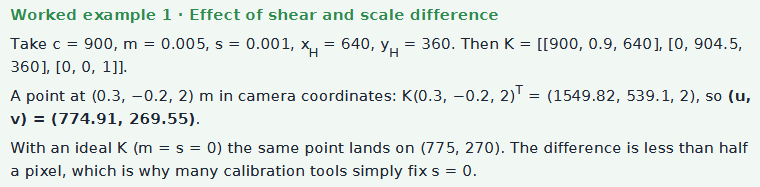

In [1]:
import numpy as np
import cv2
np.set_printoptions(suppress=True)

c,m,s =900.0, 0.005, 0.001
x_H, y_H = 640.0, 360.0
K = np.array([
    [c, c*s, x_H],
    [0, c*(1+m), y_H],
    [0, 0, 1]
])

X_c = np.array([0.3, -2.0, 2.0])
uvw = K @ X_c
print(uvw[:2]/uvw[2])

[ 774.1 -544.5]


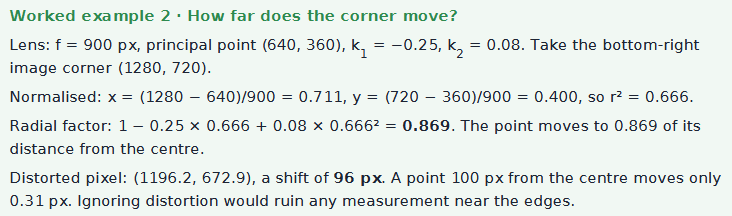

In [2]:
def distort(x,y,k1,k2,p1=0.0,p2=0.0, k3=0.0):
    r2 = x**2+y**2
    radial = 1+k1*r2+k2*r2**2+k3*r2**3
    x_d = x * radial + 2 * p1 * x * y + p2 * (r2 + 2 * x**2)
    y_d = y * radial + p1 * (r2 + 2 * y**2) + 2 * p2 * x * y
    return x_d, y_d

K = np.array([[900.0,0,640],[0,900.0,360],[0,0,1]])
dist = np.array([-0.25, 0.08, 0.0, 0.0, 0.0])

x,y = (1280-640)/900, (720-360)/900
x_d, y_d = distort(x,y, -0.25, 0.08)
print(900*x_d+640, 900*y_d+360)

# The same with OpenCV
print(cv2.projectPoints(np.array([[x, y, 1.0]]), np.zeros(3), np.zeros(3), K, dist)[0].ravel())

# And back again: undistort the distorted pixel
print(cv2.undistortPoints(np.array([[[1196.18, 672.85]]]), K, dist, P=K).ravel()) # ~[1280. 720.]
    

1196.1795396555403 672.8509910562415
[1196.17953966  672.85099106]
[1279.95788427  719.97487161]
